<h1 align=center> NumPy for AI </h1>

#### **Contents**
1. Creating Arrays
2. Array Attributes & Data Types
3. Array Operations (Vectorization)
4. Indexing and Slicing
5. Broadcasting (In Depth)
6. Reshaping, Resizing, Stacking & Splitting
7. Statistical Operations (with Axis Explained)
8. Linear Algebra Operations
9. Random Numbers
10. Handling Missing Data (NaN)
11. Saving and Loading Arrays
12. NumPy for AI — Practical Examples (Advanced)
    - 12.1 One-Hot Encoding
    - Normalizing / Standardizing Data
    - A Single Neuron's Forward Pass — Pure NumPy
    - A Full Dense Layer (Multiple Neurons) — Batched
    - Gradient Descent From Scratch
    - Cosine Similarity — the Core Operation Behind Vector Search / RAG

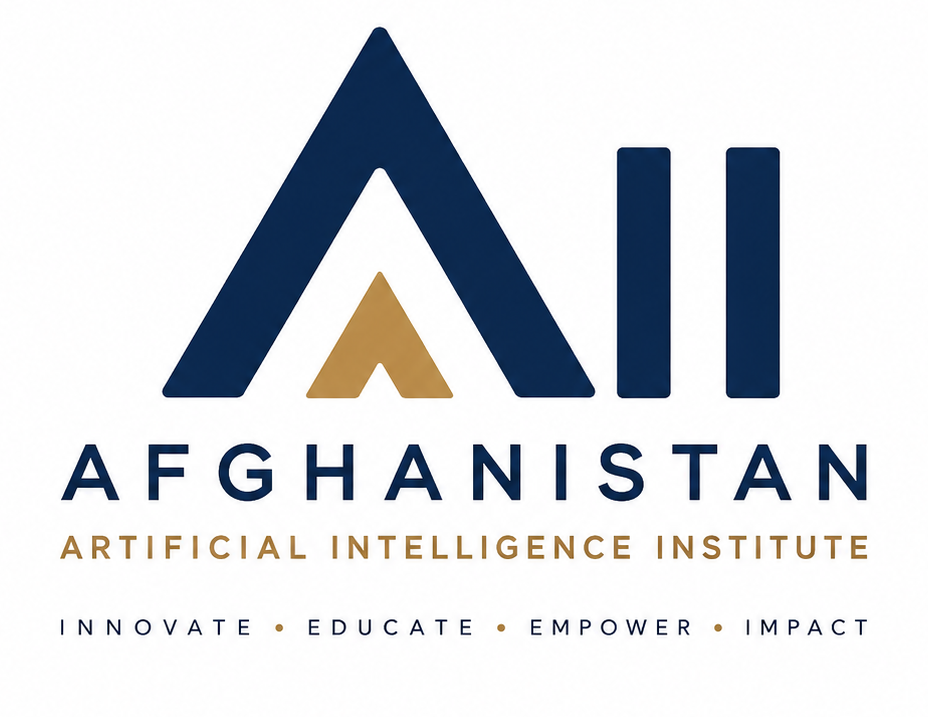

## 0. Introduction

- NumPy (Numerical Python) is an open source Python library that’s widely used in science and engineering.
- It is drastically faster than native Python lists because it stores data in contiguous memory blocks and utilizes optimized C code under the hood.

**Why NumPy matters for AI specifically:** every tensor library (TensorFlow, PyTorch) borrows its array API almost directly from NumPy. Data loading, preprocessing, and even the math inside a neural network's forward pass are all NumPy operations underneath.

In [10]:
import numpy as np
print(np.__version__)

1.26.4


## 1. Creating Arrays
- In computer programming, an array is a structure for storing and retrieving data.
  - Heterogeneous means an array can contain different types of data. `data = [10, "Hello", 3.14, True]`
  - Homogeneous array means an array where all elements are of the same data type.`names = ["John", "Sara", "Mike"]`
    
`ndarray` is NumPy's core object — a homogeneous, n-dimensional array (every element must share the same dtype).



In [11]:
arr1 = np.array([1, 2, 3, 4])                     # 1D array (vector)
arr2 = np.array([[1, 2, 3], [4, 5, 6]])            # 2D array (matrix)
arr3 = np.array([[[1, 2], [3, 4]], [[5, 6], [7, 8]]])  # 3D array (tensor)

print("1D:", arr1)
print("2D:\n", arr2)
print("3D:\n", arr3)

1D: [1 2 3 4]
2D:
 [[1 2 3]
 [4 5 6]]
3D:
 [[[1 2]
  [3 4]]

 [[5 6]
  [7 8]]]


`Dimension` = number of indexes/levels needed to reach a value.

**Array creation shortcuts** — you'll use these constantly to build arrays from scratch:

In [12]:
zeros = np.zeros((3, 3)) 
ones = np.ones((2, 4))
full = np.full((2, 2), 7)
identity = np.eye(3)
rng = np.arange(0, 10, 2)
lin = np.linspace(0, 1, 5)
empty = np.empty((2, 2))

print(zeros, "\n")
print(ones, "\n")
print(full, "\n")
print(identity, "\n")
print(rng, "\n")
print(lin)

[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]] 

[[1. 1. 1. 1.]
 [1. 1. 1. 1.]] 

[[7 7]
 [7 7]] 

[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]] 

[0 2 4 6 8] 

[0.   0.25 0.5  0.75 1.  ]


## 2. Array Attributes & Data Types

In [13]:
arr = np.array([[1, 2, 3], [4, 5, 6]])

print("Shape:", arr.shape)
print("Dimensions:", arr.ndim)
print("Size:", arr.size)
print("Dtype:", arr.dtype)
print("Item size (bytes):", arr.itemsize)
print("Total bytes:", arr.nbytes)

Shape: (2, 3)
Dimensions: 2
Size: 6
Dtype: int32
Item size (bytes): 4
Total bytes: 24


**Data types** — matters a lot for memory and for matching what a deep learning framework expects:

In [14]:
arr_float32 = np.array([1, 2, 3], dtype=np.float32)
arr_int8 = np.array([1, 2, 3], dtype=np.int8)
print(arr_float32.dtype, arr_int8.dtype)

arr = np.array([1.7, 2.3, 3.9])
print(arr.astype(int))
print(np.round(arr).astype(int))

float32 int8
[1 2 3]
[2 2 4]


1. Integer Types
| Data type |              Size |                     Approximate range |
| --------- | ----------------: | ------------------------------------: |
| `int8`    |   8 bits (1 byte) |                           -128 to 127 |
| `int16`   | 16 bits (2 bytes) |                     -32,768 to 32,767 |
| `int32`   | 32 bits (4 bytes) |           -2.1 billion to 2.1 billion |
| `int64`   | 64 bits (8 bytes) | -9.22 quintillion to 9.22 quintillion |

2. Unsigned Integers
| Data type |    Size |                  Range |
| --------- | ------: | ---------------------: |
| `uint8`   |  8 bits |               0 to 255 |
| `uint16`  | 16 bits |            0 to 65,535 |
| `uint32`  | 32 bits |     0 to ~4.29 billion |
| `uint64`  | 64 bits | 0 to ~18.4 quintillion |

3. Floating-point Types
| Type      |    Size | Example           |
| --------- | ------: | ----------------- |
| `float16` | 16 bits | `3.14`            |
| `float32` | 32 bits | `3.14159`         |
| `float64` | 64 bits | `3.1415926535...` |


**Why this matters for AI:** TensorFlow/PyTorch models almost always expect `float32` inputs. Loading data as `float64` by default and feeding it directly into a model wastes memory and can cause dtype mismatch errors.

## 3. Array Operations (Vectorization)

In [15]:
arr1 = np.array([1, 2, 3, 4])
arr2 = np.array([10, 20, 30, 40])

print("Addition:", arr1 + arr2)
print("Multiplication:", arr1 * arr2)
print("Square Root:", np.sqrt(arr1))
print("Exponent:", np.exp(arr1))
print("Power:", arr1 ** 2)
print("Log:", np.log(arr1))

Addition: [11 22 33 44]
Multiplication: [ 10  40  90 160]
Square Root: [1.         1.41421356 1.73205081 2.        ]
Exponent: [ 2.71828183  7.3890561  20.08553692 54.59815003]
Power: [ 1  4  9 16]
Log: [0.         0.69314718 1.09861229 1.38629436]


**Vectorization vs. Python loops** — the single most important performance idea in NumPy:

In [16]:
import time

n = 5_000_000
python_list = list(range(n))
np_array = np.arange(n)

start = time.time()
result = [x * 2 for x in python_list]
print("Python loop time:", time.time() - start)

start = time.time()
result = np_array * 2
print("NumPy vectorized time:", time.time() - start)

Python loop time: 0.30673694610595703
NumPy vectorized time: 0.045180559158325195


**Element-wise** means an operation is performed separately on each element of an array.

**Universal functions (ufuncs):** `np.sqrt`, `np.exp`, `np.sin`, `np.log`, etc. all operate element-wise without you writing a loop — this is what "vectorized" means in practice.

**Vectorization** means performing operations on an entire array at once, rather than writing a loop that processes each element individually.

## 4. Indexing and Slicing

In [17]:
arr = np.array([[1, 2, 3, 4], [5, 6, 7, 8], [9, 10, 11, 12]])

print(arr[1][2])
print("Element at [1, 2]:", arr[1, 2])
print("Row 1:", arr[1])
print("Column 2:", arr[:, 2])
print("Slice rows 1-2, cols 1-2:\n", arr[1:3, 1:3])

7
Element at [1, 2]: 7
Row 1: [5 6 7 8]
Column 2: [ 3  7 11]
Slice rows 1-2, cols 1-2:
 [[ 6  7]
 [10 11]]


In [18]:
arr = np.array([[1, 2, 3, 4], [5, 6, 7, 8], [9, 10, 11, 12]])
print("Elements > 5:", arr[arr > 5])
arr[arr > 10] = 0
print("After masking assignment:\n", arr)

Elements > 5: [ 6  7  8  9 10 11 12]
After masking assignment:
 [[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10  0  0]]


**Fancy indexing** — indexing with a list/array of indices:

In [19]:
arr = np.array([10, 20, 30, 40, 50])
indices = [0, 2, 4]
print(arr[indices])

matrix = np.array([[1, 2], [3, 4], [5, 6]])
print(matrix[[0, 2]])

[10 30 50]
[[1 2]
 [5 6]]


**Copy vs. View** — the #1 silent-bug source for NumPy beginners:

In [20]:
arr = np.array([1, 2, 3, 4])
view = arr[1:3]
view[0] = 999
print(arr)

arr = np.array([1, 2, 3, 4])
safe_copy = arr[1:3].copy()
safe_copy[0] = -1
print(arr)

[  1 999   3   4]
[1 2 3 4]


## 5. Broadcasting (In Depth)

Broadcasting lets NumPy operate on arrays of different shapes without explicitly copying data.

In [21]:
arr = np.array([[1, 2, 3], [4, 5, 6]])
vec = np.array([1, 0, 1])
result = arr + vec
print("Broadcasted Addition:\n", result)

Broadcasted Addition:
 [[2 2 4]
 [5 5 7]]


**Broadcasting rules explained:**

> Two shapes are compatible for broadcasting if, comparing dimensions from the **right**, each pair of dimensions is either **equal**, or **one of them is 1**.

`(3, 4)`

`(1, 4)`

In [22]:
a = np.array([[1], [2], [3]])
b = np.array([10, 20, 30])
print(a + b)

[[11 21 31]
 [12 22 32]
 [13 23 33]]


**`np.newaxis` and `expand_dims`** — needed constantly when preparing data for deep learning models:

In [23]:
arr = np.array([1, 2, 3])
print(arr.shape)

row = arr[np.newaxis, :]
col = arr[:, np.newaxis]
print(row.shape, col.shape)

batched = np.expand_dims(arr, axis=0)
print(batched.shape)

(3,)
(1, 3) (3, 1)
(1, 3)


## 6. Reshaping, Resizing, Stacking & Splitting

In [24]:
arr = np.array([[1, 2, 3, 4], [5, 6, 7, 8]])

reshaped = arr.reshape(4, 2)
print("Reshaped:\n", reshaped)

flat = arr.flatten() # Produces a 1-D copy
raveled = arr.ravel() # tries to return a view of the original array rather than making a copy
print("Flattened:", flat)
print("Reveled: ", raveled)

arr_copy = arr.copy()
arr_copy.resize(2, 2)
print("Resized:\n", arr_copy)

transposed = arr.T
print("Transposed:\n", transposed)

Reshaped:
 [[1 2]
 [3 4]
 [5 6]
 [7 8]]
Flattened: [1 2 3 4 5 6 7 8]
Reveled:  [1 2 3 4 5 6 7 8]
Resized:
 [[1 2]
 [3 4]]
Transposed:
 [[1 5]
 [2 6]
 [3 7]
 [4 8]]


**Stacking and splitting:**

In [25]:
a = np.array([1, 2, 3])
b = np.array([4, 5, 6])

print("Concatenats: ", np.concatenate([a, b]))
print("Stack: ", np.stack([a, b]))
print("Vertical Stack: ", np.vstack([a, b]))
print("Horizontal Stack: ", np.hstack([a, b]))

matrix = np.array([[1, 2, 3, 4], [5, 6, 7, 8]])
left, right = np.hsplit(matrix, 2)
print("Left: ", left, "\nRight: ", right)

Concatenats:  [1 2 3 4 5 6]
Stack:  [[1 2 3]
 [4 5 6]]
Vertical Stack:  [[1 2 3]
 [4 5 6]]
Horizontal Stack:  [1 2 3 4 5 6]
Left:  [[1 2]
 [5 6]] 
Right:  [[3 4]
 [7 8]]


## 7. Statistical Operations (with Axis Explained)

In [26]:
arr = np.array([[1, 2, 3], [4, 5, 6]])

print("Sum:", np.sum(arr))
print("Mean:", np.mean(arr))
print("Max:", np.max(arr))
print("Min:", np.min(arr))
print("Std Dev:", np.std(arr))
print("Variance:", np.var(arr))
print("Median:", np.median(arr))

Sum: 21
Mean: 3.5
Max: 6
Min: 1
Std Dev: 1.707825127659933
Variance: 2.9166666666666665
Median: 3.5


**The `axis` parameter, explained clearly:**

In [27]:
arr = np.array([[1, 2, 3],
                 [4, 5, 6]])

print(np.sum(arr, axis=0)) # axis=0 => row
print(np.sum(arr, axis=1)) # axis=1 => col

[5 7 9]
[ 6 15]


**Finding positions, not just values:**

In [28]:
predictions = np.array([0.1, 0.7, 0.05, 0.15])
print("argmax:", np.argmax(predictions))
print("argmin:", np.argmin(predictions))

scores = np.array([50, 20, 90, 10])
print("argsort:", np.argsort(scores))
print("sorted:", np.sort(scores))
print("top-2 indices:", np.argsort(scores)[-2:])

argmax: 1
argmin: 2
argsort: [3 1 0 2]
sorted: [10 20 50 90]
top-2 indices: [0 2]


**Conditional selection with `np.where` and clipping with `np.clip`:**

In [29]:
arr = np.array([1, -2, 3, -4, 5])
print(np.where(arr > 0, arr, 0))
print(np.clip(arr, -2, 2)) # is used to limit values in a NumPy array to a specified minimum and maximum.

[1 0 3 0 5]
[ 1 -2  2 -2  2]


## 8. Linear Algebra Operations

In [30]:
arr1 = np.array([[1, 2], [3, 4]])
arr2 = np.array([[5, 6], [7, 8]])

dot_product = np.dot(arr1, arr2)
print("Dot Product:\n", dot_product)

det = np.linalg.det(arr1)
print("Determinant:", det)

Dot Product:
 [[19 22]
 [43 50]]
Determinant: -2.0000000000000004


**Matrix multiplication — `@` and the batched case:**

In [31]:
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])

print(A @ B)
print(np.matmul(A, B))

batch_A = np.random.rand(32, 4, 2) # Think of these as 32 pairs of matrices, each 4 X 2 
batch_B = np.random.rand(32, 2, 3)
batch_result = batch_A @ batch_B
print(batch_result.shape)

[[19 22]
 [43 50]]
[[19 22]
 [43 50]]
(32, 4, 3)


**More linear algebra tools:**

In [32]:
A = np.array([[4, 2], [1, 3]])

print("Inverse:\n", np.linalg.inv(A))
eigenvalues, eigenvectors = np.linalg.eig(A)
print("Eigenvalues:", eigenvalues)
print("Eigenvectors:\n", eigenvectors)

b = np.array([1, 2])
x = np.linalg.solve(A, b) # it solves Ax = b

print("Solution x:", x)

Inverse:
 [[ 0.3 -0.2]
 [-0.1  0.4]]
Eigenvalues: [5. 2.]
Eigenvectors:
 [[ 0.89442719 -0.70710678]
 [ 0.4472136   0.70710678]]
Solution x: [-0.1  0.7]


## 9. Random Numbers

In [33]:
rand_arr = np.random.rand(3, 3)
rand_ints = np.random.randint(1, 10, size=(3, 3))
print(rand_arr)
print(rand_ints)

arr = np.array([1, 2, 3, 4, 5])
np.random.shuffle(arr)
print("Shuffled:", arr)

[[0.62502919 0.31654967 0.81641078]
 [0.50151546 0.07089158 0.31286316]
 [0.9352971  0.85068026 0.9819057 ]]
[[3 2 4]
 [8 1 1]
 [5 5 1]]
Shuffled: [3 2 4 5 1]


**Reproducibility and other distributions:**

`np.random.seed(42)`
- The seed makes the results reproducible.
- So if you run the same code again, you'll get the same random values.

In [34]:
np.random.seed(42)

normal_vals = np.random.randn(1000) # Generates 1,000 random numbers from a standard normal distribution: μ=0,σ=1
normal_custom = np.random.normal(loc=5, scale=2, size=1000) # loc=5 → mean = 5, scale=2 → standard deviation = 2
# size=1000 → generate 1,000 values

choice = np.random.choice([10, 20, 30, 40], size=3, replace=False)
print(choice)

rng = np.random.default_rng(seed=42) # This creates a dedicated random-number generator
print(rng.random((2, 2)))
print(rng.integers(0, 10, size=5))

[10 40 30]
[[0.77395605 0.43887844]
 [0.85859792 0.69736803]]
[2 0 5 9 7]


**Why this matters for AI:** weight initialization in every neural network layer samples from a distribution like this; train/test splits use shuffling; and `seed()` is what makes your results reproducible.

## 10. Handling Missing Data (NaN)

In [35]:
arr = np.array([1, 2, np.nan, 4, np.nan, 6])

print(np.isnan(arr))
print(np.sum(np.isnan(arr)))
print(np.mean(arr))

print(np.nanmean(arr)) # computes the average of the elements in an array while ignoring any NaN 
print(np.nansum(arr))
print(np.nanmax(arr))

clean = np.where(np.isnan(arr), 0, arr)
print(clean)

[False False  True False  True False]
2
nan
3.25
13.0
6.0
[1. 2. 0. 4. 0. 6.]


## 11. Saving and Loading Arrays

In [36]:
arr = np.array([[1, 2, 3], [4, 5, 6]])

np.save('my_array.npy', arr)
loaded_arr = np.load('my_array.npy')
print("Loaded:\n", loaded_arr)

Loaded:
 [[1 2 3]
 [4 5 6]]


- The below code shows how to save and load multiple NumPy arrays using an .npz file

In [37]:
np.savez('arrays.npz', a=arr, b=arr * 2)
data = np.load('arrays.npz')
print(data['a'], data['b'])

[[1 2 3]
 [4 5 6]] [[ 2  4  6]
 [ 8 10 12]]


In [38]:
np.savetxt('array.csv', arr, delimiter=',')
loaded_txt = np.loadtxt('array.csv', delimiter=',')
print(loaded_txt)

[[1. 2. 3.]
 [4. 5. 6.]]


## 12. NumPy for AI — Practical Examples (Advanced)

This is where NumPy stops being abstract and becomes visibly "the thing AI runs on".

### 12.1 One-Hot Encoding

In [39]:
labels = np.array([0, 2, 1, 0, 3])
num_classes = 4
one_hot = np.eye(num_classes)[labels]
print(one_hot)

[[1. 0. 0. 0.]
 [0. 0. 1. 0.]
 [0. 1. 0. 0.]
 [1. 0. 0. 0.]
 [0. 0. 0. 1.]]


### 12.2 Normalizing / Standardizing Data

**Normalization:** usually means scaling data to a particular range or scale.
- One common method is standardization (Z-score normalization):

$$ z = \frac{x-\mu}{\sigma} $$

In [40]:
data = np.array([[10, 200], [15, 400], [20, 600], [12, 300]], dtype=float)

normalized = (data - data.min(axis=0)) / (data.max(axis=0) - data.min(axis=0))
print("Min-Max Normalized:\n", normalized)

standardized = (data - data.mean(axis=0)) / data.std(axis=0)
print("Standardized:\n", standardized)

Min-Max Normalized:
 [[0.   0.  ]
 [0.5  0.5 ]
 [1.   1.  ]
 [0.2  0.25]]
Standardized:
 [[-1.12832963 -1.18321596]
 [ 0.19911699  0.16903085]
 [ 1.52656362  1.52127766]
 [-0.59735098 -0.50709255]]


### 12.3 A Single Neuron's Forward Pass — Pure NumPy

In [41]:
inputs = np.array([1.0, 2.0, 3.0])
weights = np.array([0.2, 0.4, -0.1])
bias = 0.5

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

z = np.dot(inputs, weights) + bias
output = sigmoid(z)
print("Neuron output:", output)

Neuron output: 0.7685247834990175


### 12.4 A Full Dense Layer (Multiple Neurons) — Batched

In [42]:
X = np.array([[1.0, 2.0, 3.0],
              [0.5, 1.5, 2.5],
              [2.0, 1.0, 0.5],
              [1.0, 1.0, 1.0]])

W = np.array([[0.1, 0.4],
              [0.2, 0.5],
              [0.3, 0.6]])
b = np.array([0.1, 0.1])

layer_output = X @ W + b
print("Layer output:\n", layer_output)
print("Output shape:", layer_output.shape)

Layer output:
 [[1.5  3.3 ]
 [1.2  2.55]
 [0.65 1.7 ]
 [0.7  1.6 ]]
Output shape: (4, 2)


### 12.5 Gradient Descent From Scratch

This is an example of `gradient descent` — an optimization algorithm used heavily in machine learning.



You're trying to find the minimum of:

f(x)=(x−3)^2

This is the gradient descent rule:

x_new ​= x_old ​− learningrate × gradient

In [43]:
def f(x):
    return (x - 3) ** 2

def gradient(x):
    return 2 * (x - 3)

x = np.array(0.0)
learning_rate = 0.1

for step in range(30):
    grad = gradient(x)
    x = x - learning_rate * grad

print("Converged x:", x)

Converged x: 2.996286179882144


### 12.6 Cosine Similarity — the Core Operation Behind Vector Search / RAG

In [44]:
def cosine_similarity(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

query_embedding = np.array([0.2, 0.8, 0.1])
doc_embeddings = np.array([
    [0.1, 0.9, 0.05],
    [0.9, 0.1, 0.2],
    [0.25, 0.75, 0.15],
])

similarities = np.array([cosine_similarity(query_embedding, doc) for doc in doc_embeddings])
print("Similarities:", similarities)
print("Most similar document index:", np.argmax(similarities))

Similarities: [0.98892595 0.36348313 0.99489492]
Most similar document index: 2


## Quick Reference — Most-Used NumPy Functions for AI

```python
# Creation
np.array(), np.zeros(), np.ones(), np.full(), np.eye(), np.arange(), np.linspace()

# Inspecting
arr.shape, arr.ndim, arr.size, arr.dtype, arr.astype()

# Indexing
arr[mask], arr[[i, j, k]], arr[:, np.newaxis], np.expand_dims()

# Reshaping / combining
arr.reshape(), arr.flatten(), arr.T, np.concatenate(), np.stack(), np.vstack(), np.hstack()

# Math / stats
np.sum(), np.mean(), np.std(), np.min(), np.max(), axis=0 / axis=1
np.argmax(), np.argmin(), np.argsort(), np.where(), np.clip()

# Linear algebra
A @ B, np.dot(), np.linalg.inv(), np.linalg.det(), np.linalg.eig(), np.linalg.solve(), np.linalg.norm()

# Random
np.random.seed(), np.random.rand(), np.random.randn(), np.random.randint(), np.random.choice()

# Missing data
np.isnan(), np.nanmean(), np.nansum()

# I/O
np.save(), np.load(), np.savez(), np.savetxt(), np.loadtxt()
```

---
# Practice Questions — Active Learning

Try each one yourself in the empty code cell below it *before* checking the notes above.

**Q1.** Create a 4x4 identity matrix, then use `np.where` to replace every `0` in it with `-1`, leaving the `1`s unchanged.

In [45]:
# Write your answer here


**Q2.** Given `arr = np.arange(24).reshape(2, 3, 4)`, print its shape, then compute the sum along `axis=0`, `axis=1`, and `axis=2` separately. Explain in a comment what each result represents.

In [46]:
# Write your answer here


**Q3.** Demonstrate the copy-vs-view trap yourself: create an array, take a slice (a view), modify the slice, and show the original array changed. Then repeat using `.copy()` and show it does NOT change.

In [47]:
# Write your answer here


**Q4.** Write a function `min_max_scale(arr)` that scales any 1D NumPy array to the range [0, 1] using the min-max formula from section 12.2.

In [48]:
# Write your answer here


**Q5.** Using `np.random.default_rng(seed=1)`, generate a 5x5 matrix of random integers between 1 and 100. Then find: the max value, its row/column position, and the column-wise mean.

*Hint: np.unravel_index(arr.argmax(), arr.shape)*

In [49]:
# Write your answer here


**Q6.** Implement a simple ReLU activation function using only `np.where` or `np.maximum`, and apply it to `np.array([-3, -1, 0, 2, 5])`.

In [50]:
# Write your answer here


**Q7.** **Challenge:** Extend the batched Dense layer example (12.4) by adding a second layer mapping the 2 outputs down to 1 output per sample. Print the final shape -- it should be `(4, 1)`.

In [51]:
# Write your answer here


**Q8.** **Challenge:** Add TWO more candidate document embeddings to the cosine similarity example (12.6), and print all similarity scores sorted from most to least similar using `np.argsort`.

In [52]:
# Write your answer here
